In [15]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis

Foram criadas 3 pastas a partir das imagens originais. Uma das pastas recebeu as imagens sem marcador, outra pasta recebeu as imagens marcadas sem rótulo e a terceira pasta recebeu as imagens marcadas com os rótulos. Nesse notebook, estamos trabalhando com 40 (iniciais) imagens marcadas com os rótulos.

In [21]:
novas_imagens = "./data/realcadas_verde_HBMC/"
img_key = 0 #Chave da primeira imagem

lista_novas_img = os.listdir(novas_imagens) #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens
#lista_novas_img

31

Visualização das imagens (x): Melhor resolução 300x300

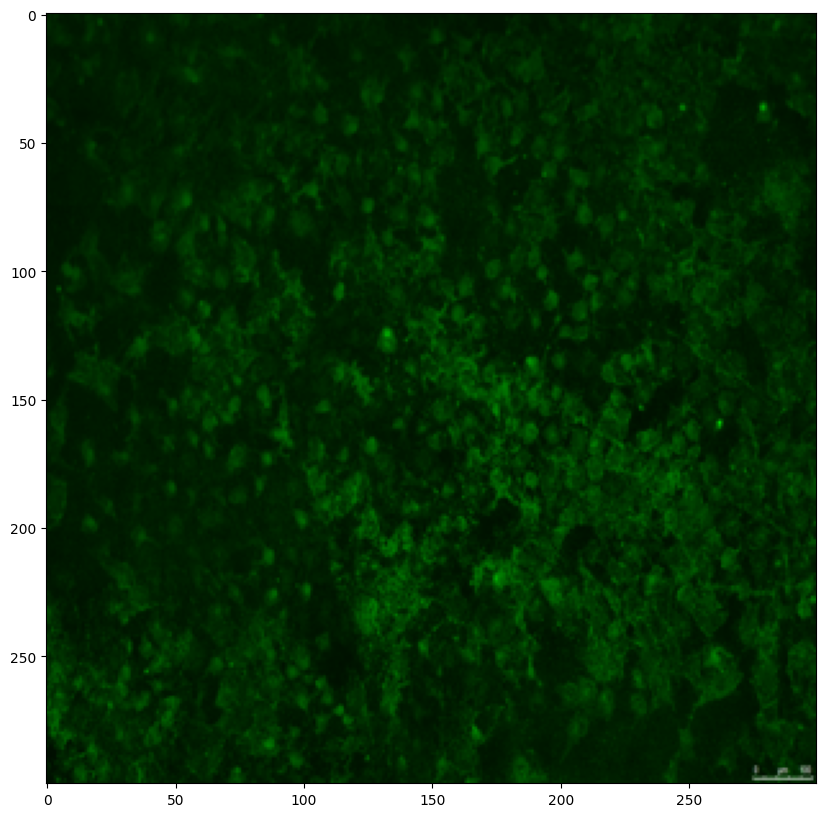

In [22]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

#1. Original orientation of the image.

Formatting all images that are saved in the directory into an array

In [24]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img] #cortando informações da imagem
y_rotulo_imagem = [(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = y_rotulo_imagem
print(len(y_rotulo_imagem)) #verificando o numero de rótulos corresponde o numero de imagens
print(y_rotulo_imagem)

31
['0.154757', '0.138553', '0.160986', '0.127821', '0.180817', '0.164756', '0.166864', '0.188495', '0.163527', '0.154551', '0.435090', '0.173011', '0.408415', '0.307947', '0.428906', '0.436615', '0.403093', '0.371291', '0.370098', '0.318978', '0.186781', '0.223602', '0.216760', '0.185403', '0.229978', '0.195044', '0.197190', '0.231501', '0.173558', '0.190686', '0.165657']


In [25]:
lista_imagens_camp_claro = [] #lista vazia onde vai ser armazenado os dados
for file in lista_novas_img[:]:  #laço pra salvar todas as imagens
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test) #abrir a imagem
    img = img.resize(resize_img) #formatando em 300x300
    img = np.asarray(img)[:,:,:3] #formatando em array
    lista_imagens_camp_claro.append(img)  #adicionando cada imagem
np.asarray(lista_imagens_camp_claro).shape #verificando quantas imagens foram salvas em qual tamnho e camadas

(31, 300, 300, 3)

#2. Saving inverted images from left to right

label (80 - doubled) - dobrando o numero de rótulos

In [26]:
# #dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

62

In [27]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(62, 300, 300, 3)

#3. Saving inverted images from bottom to top

y = label (120 - doubled)

In [28]:
# #dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

93

In [29]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(93, 300, 300, 3)

# 4. Saving the images flipped upside down.

label (160 - doubled) - dobrando o numero de rótulos

In [30]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

124

In [31]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(124, 300, 300, 3)

Salvando em uma lista as imagens em diferentes orientações.

In [32]:
data = timeProcess()[1]
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_imagem_100_resized_regre_HBMEC_realce_'+data+'.gz')

['./data/realcadas_verde_HBMC/lista_imagem_100_resized_regre_HBMEC_realce_2026-10-17.gz']

In [33]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_rotulo_100_resized_regre_balb-roseta_'+data+'.gz')

['./data/realcadas_verde_HBMC/lista_rotulo_100_resized_regre_balb-roseta_2026-10-17.gz']

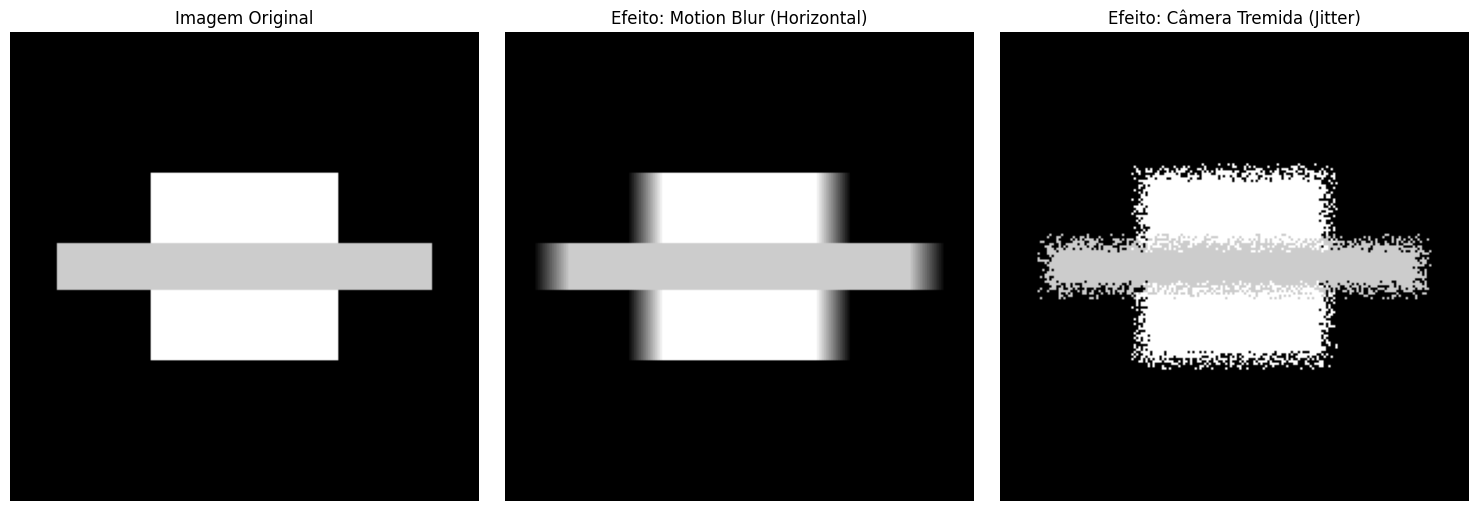

In [36]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import convolve

# 1. Criar uma imagem de exemplo (uma matriz preta com um quadrado branco no centro)
# Se quiser usar sua própria imagem, use: imagem = plt.imread('sua_imagem.png')
np.random.seed(42)
imagem = np.zeros((200, 200))
imagem[60:140, 60:140] = 1.0  # Quadrado central
imagem[90:110, 20:180] = 0.8  # Uma linha cruzando para destacar o desfoque

# 2. Efeito Tremido 1: Motion Blur (Desfoque de movimento horizontal)
tamanho_kernel = 15
kernel_motion = np.zeros((tamanho_kernel, tamanho_kernel))
# Preenche a linha central do kernel para simular movimento horizontal
kernel_motion[tamanho_kernel // 2, :] = 1
kernel_motion /= tamanho_kernel  # Normaliza o kernel

imagem_motion_blur = convolve(imagem, kernel_motion)

# 3. Efeito Tremido 2: Pixel Jitter (Tremor caótico/ruído de câmera)
fator_tremor = 4  # Quantidade máxima de pixels que o bloco vai se mover
imagem_jitter = imagem.copy()
for i in range(fator_tremor, imagem.shape[0] - fator_tremor):
    for j in range(fator_tremor, imagem.shape[1] - fator_tremor):
        # Desloca aleatoriamente o pixel atual
        di = np.random.randint(-fator_tremor, fator_tremor + 1)
        dj = np.random.randint(-fator_tremor, fator_tremor + 1)
        imagem_jitter[i, j] = imagem[i + di, j + dj]

# 4. Exibir os resultados usando Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Imagem Original
axes[0].imshow(imagem, cmap='gray')
axes[0].set_title('Imagem Original')
axes[0].axis('off')

# Imagem com Motion Blur
axes[1].imshow(imagem_motion_blur, cmap='gray')
axes[1].set_title('Efeito: Motion Blur (Horizontal)')
axes[1].axis('off')

# Imagem com Jitter
axes[2].imshow(imagem_jitter, cmap='gray')
axes[2].set_title('Efeito: Câmera Tremida (Jitter)')
axes[2].axis('off')

plt.tight_layout()
plt.show()
